[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/02-split-and-metrics.ipynb)

# Splitting and Ranking Metrics: How to Test a Recommender

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build a per-user, time-ordered train/test split and state what counts as a hit.</li>
<li>Compute Precision@k, Recall@k, hit rate, AP@k and NDCG@k, and verify them by hand on a small example.</li>
<li>Show how a random split inflates every personalised model, and why sampled metrics mislead.</li>
<li>Judge whether two recommenders really differ, with a paired confidence interval over users.</li>
</ul>
</div>

**Prerequisites:** [Framing the problem](01-framing.ipynb) and [Splitting Strategy](../lifecycle/05-splitting.ipynb). **Dataset:** MovieLens small. **Time:** about 35 minutes.

## The situation

Every claim in the rest of this track is of the form "model A recommends better than model B". That sentence is only as trustworthy as the **test** behind it. Recommenders are unusually easy to test dishonestly: the data is a time-ordered record of choices, users are both the thing we split and the thing we average over, and the metrics have several "reasonable" definitions that give very different numbers. This page fixes one protocol and shows what goes wrong with the tempting alternatives.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

## Maths ↔ code

For one user, let the model's list be $i_1, \dots, i_k$ (best first) and let $\text{rel}_j = 1$ if $i_j$ is a hit, $|\text{Rel}|$ the number of hits the user really has.

$$\text{P@}k=\frac{1}{k}\sum_{j\le k}\text{rel}_j,\qquad \text{R@}k=\frac{1}{|\text{Rel}|}\sum_{j\le k}\text{rel}_j,\qquad \text{AP@}k=\frac{1}{\min(k,|\text{Rel}|)}\sum_{j\le k}\text{P@}j\cdot\text{rel}_j$$

$$\text{NDCG@}k=\frac{\text{DCG@}k}{\text{IDCG@}k},\qquad \text{DCG@}k=\sum_{j\le k}\frac{\text{rel}_j}{\log_2(j+1)}$$

`rs.rank_metrics(top, relevant)` computes all of them per user; `rs.evaluate(scores, train, relevant, k)` first hides each user's training items, ranks the rest and then calls it.

## 1. The protocol

For **every user**, the latest 20% of their ratings become the test set and the earlier 80% the training set. A test item is a **hit** if the user rated it **4 stars or more**. The model sees only the training ratings and must rank every movie the user has *not* rated in training.

In [2]:
ratings = load_movielens().ratings
task = rs.make_task(ratings, like=4.0, how="time", test_frac=0.2)

rs.assert_chronological(task.train, task.test)         # no user trains on anything newer than their test ratings
n_hits = np.asarray(task.relevant.sum(axis=1)).ravel()
print(f"train {len(task.train):,} ratings | test {len(task.test):,} ratings, of which {task.relevant.nnz:,} are hits (>= 4 stars)")
print(f"users with at least one hit: {(n_hits > 0).sum()} of {len(n_hits)}; the other {(n_hits == 0).sum()} cannot be scored and are left out")
print(f"hits per scored user: median {np.median(n_hits[n_hits > 0]):.0f}, max {n_hits.max():.0f}")

train 80,672 ratings | test 20,164 ratings, of which 9,358 are hits (>= 4 stars)
users with at least one hit: 592 of 610; the other 18 cannot be scored and are left out
hits per scored user: median 8, max 241


The split is 80,672 training ratings and 20,164 test ratings, and **9,358 of the test ratings are hits**: about 46% of what users rated late in their history was 4 stars or more. Eighteen users (3%) have no hit in their latest 20% and are left out, since for them nothing can be "found". The median scored user has only **8 hits**, so one user's score rests on a handful of movies and is noisy; only the average over hundreds of users is stable, which is why section 6 compares models *per user*.

## 2. The metrics, checked by hand

A tiny example before trusting any library: six movies, a user whose hits are movies 2 and 5, and a list `[2, 0, 5]` (a hit, a miss, a hit).

In [3]:
top = np.array([[2, 0, 5]])
import scipy.sparse as sp
relevant = sp.csr_matrix(np.array([[0, 0, 1, 0, 0, 1]]))

m = rs.rank_metrics(top, relevant).iloc[0]

# by hand
precision = 2 / 3                                           # 2 hits in 3 slots
recall = 2 / 2                                              # both of the user's hits were found
ap = (1 / 1 + 2 / 3) / min(3, 2)                            # precision at each hit's rank (1/1 and 2/3), averaged over min(k, |Rel|)
dcg = 1 / np.log2(1 + 1) + 1 / np.log2(3 + 1)               # hits at ranks 1 and 3
idcg = 1 / np.log2(1 + 1) + 1 / np.log2(2 + 1)              # the best possible list has them at ranks 1 and 2
by_hand = dict(precision=precision, recall=recall, ap=ap, ndcg=dcg / idcg)

for name, value in by_hand.items():
    assert np.isclose(m[name], value), name
print(pd.Series(by_hand).round(4).to_dict())

{'precision': 0.6667, 'recall': 1.0, 'ap': 0.8333, 'ndcg': 0.9197}


All four hand-computed values agree with the library. Both hits were found (recall 1.0), but one sits at rank 3 instead of rank 2, so AP is 0.83 and NDCG is 0.92 rather than 1.0. That is the whole difference between the order-blind metrics (precision, recall) and the order-aware ones (AP, NDCG).

## 3. How the metrics move with the list length

Take the simplest recommender there is, **popularity**: score every movie by how many training users rated it, and give everyone the same list. Rank all movies, then look at the top $k$ for several $k$.

,precision,recall,hit,ap,ndcg
k,,,,,
1,0.1030,0.0078,0.1030,0.1030,0.1030
3,0.0783,0.0195,0.1841,0.0610,0.0841
5,0.0686,0.0302,0.2382,0.0465,0.0774
10,0.0571,0.0496,0.3209,0.0355,0.0743
20,0.0477,0.0836,0.4240,0.0320,0.0802
50,0.0351,0.1480,0.5828,0.0327,0.0981


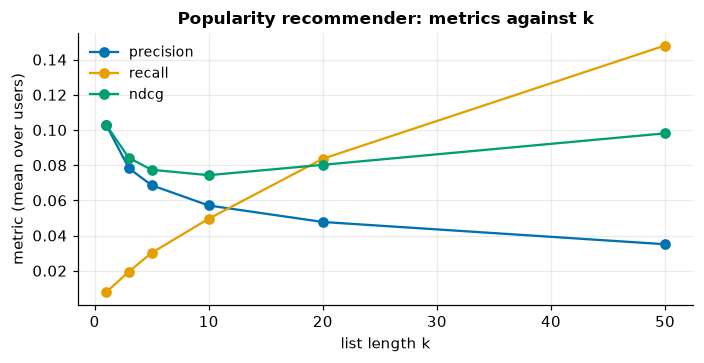

In [4]:
n_users = task.X.shape[0]
popular = rs.broadcast(rs.popularity(task.B), n_users)
top50 = rs.top_k(popular, task.B, k=50)                   # the best 50 unseen movies for every user

rows = {k: rs.rank_metrics(top50[:, :k], task.relevant)[["precision", "recall", "hit", "ap", "ndcg"]].mean() for k in (1, 3, 5, 10, 20, 50)}
by_k = pd.DataFrame(rows).T.rename_axis("k")
display(by_k)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for col, color in zip(["precision", "recall", "ndcg"], [style.BLUE, style.ORANGE, style.GREEN]):
    ax.plot(by_k.index, by_k[col], marker="o", color=color, label=col)
ax.set(xlabel="list length k", ylabel="metric (mean over users)", title="Popularity recommender: metrics against k"); ax.legend()
plt.tight_layout(); plt.show()

Three readings of the table. **Precision falls and recall rises with k** (0.103 to 0.035, and 0.008 to 0.148): a longer list finds more of what the user liked and fills up with misses. **Hit rate** says a single popularity list contains at least one liked movie for 32% of users at k = 10. And **NDCG is not monotone in k** (0.103, 0.084, 0.077, 0.074, 0.080, 0.098), because the best possible list also changes with k. So always quote k, and never compare an NDCG@10 with an NDCG@20. The rest of the track uses **k = 10**.

## 4. What goes wrong (1): a random split flatters every personalised model

The most common mistake in recommender evaluation is to hold out a *random* 20% of each user's ratings instead of the *latest* 20%. It looks equivalent and it is not. Compare three models on both splits: a **random** list (a sanity check, it should not care), **popularity**, and an **item-item** model that recommends movies similar to those the user has (built on [page 3](03-baselines.ipynb)).

In [5]:
def score_models(t):
    return {
        "random list": np.random.default_rng(0).random(t.B.shape),
        "popularity": rs.broadcast(rs.popularity(t.B), t.B.shape[0]),
        "item-item": rs.item_knn_scores(t.B, rs.item_similarity(t.B, k=50, shrink=10)),
    }

per_user, results = {}, {}
for how in ("time", "random"):
    t = rs.make_task(ratings, how=how)
    for name, S in score_models(t).items():
        per_user[(how, name)] = rs.evaluate(S, t.B, t.relevant, k=10)["ndcg"]
        results[(how, name)] = per_user[(how, name)].mean()

ndcg = pd.Series(results).unstack(0)[["time", "random"]]
ndcg["random / time"] = ndcg["random"] / ndcg["time"]
display(ndcg)
assert 0.9 < ndcg.loc["random list", "random / time"] < 1.1                  # the control does not care
assert ndcg.loc["item-item", "random / time"] > 2.5 and ndcg.loc["popularity", "random / time"] > 1.8

rnd_train, rnd_test = rs.split_per_user(ratings, how="random")
newest_train = rnd_train.groupby("userId")["timestamp"].max()
older = (rnd_test["timestamp"] < rnd_test["userId"].map(newest_train)).mean()
assert older > 0.95
print(f"in the random split, {older:.1%} of test ratings are older than a training rating from the same user")

,time,random,random / time
item-item,0.0883,0.2661,3.0152
popularity,0.0743,0.1548,2.0826
random list,0.0023,0.0022,0.9931


in the random split, 98.9% of test ratings are older than a training rating from the same user


The random-list row is the control: it learns nothing, so it scores the same (ratio 0.99) on both splits. Everything else changes. **Popularity roughly doubles (2.1 times) and the item-item model triples (3.0 times)** when the test ratings are chosen at random, because 98.9% of those test ratings are *older* than a training rating from the same user: the model has already seen where the user's taste went next. Personalised models exploit that most, which also distorts the comparison. Item-item looks **1.7 times** better than popularity on the random split and **1.2 times** better on the honest one. The gap between them is 0.111 NDCG on the random split and 0.014 on the honest one: a leaky protocol makes personalisation look about eight times more valuable than it is.

## 5. What goes wrong (2): sampled metrics

Ranking all 9,000-plus movies feels expensive, so a popular shortcut is to rank each hit only against **99 randomly chosen movies** the user has not rated, and ask whether it lands in the top 10. The numbers that come out look wonderful. Compare the two on the same hits:

In [6]:
rng = np.random.default_rng(0)
seen = task.B.toarray() > 0
hit_matrix = task.relevant.toarray() > 0

def hit_rate_full_vs_sampled(S):
    full, sampled = [], []
    for u in np.flatnonzero(hit_matrix.any(axis=1)):
        others = np.flatnonzero(~seen[u] & ~hit_matrix[u])               # unseen movies that are not hits
        for h in np.flatnonzero(hit_matrix[u]):
            full.append((S[u, others] > S[u, h]).sum() < 10)              # fewer than 10 movies beat this hit among ALL others
            negatives = rng.choice(others, 99, replace=False)
            sampled.append((S[u, negatives] > S[u, h]).sum() < 10)        # ... among 99 random ones
    return np.mean(full), np.mean(sampled)

models = score_models(task)
table = pd.DataFrame({name: hit_rate_full_vs_sampled(models[name]) for name in models}, index=["rank among all", "rank among 99 sampled"]).T
table["inflation"] = table["rank among 99 sampled"] / table["rank among all"]
assert table["inflation"].min() > 10
table.rename_axis("hit-rate@10 per hit")

,rank among all,rank among 99 sampled,inflation
hit-rate@10 per hit,,,
random list,0.0014,0.1023,73.6154
popularity,0.0419,0.5954,14.2143
item-item,0.0518,0.6724,12.9732


Among all candidate movies, popularity puts a liked movie in the top ten for 4.2% of hits and the item-item model for 5.2%. Among 99 sampled candidates the same models score **59.5% and 67.2%**, an inflation of 14 and 13 times. Even the random list reaches 10%, which is just chance (ten slots out of a hundred). A reader seeing "hit rate 67%" would think the system is nearly always right; in truth it places a given liked movie in the top ten about one time in twenty. In this data the *ordering* of the models survived, but the size of the gap did not (1.24 times in the full ranking, 1.13 times sampled). Sampled metrics are cheap and wrong; use the full ranking.

## 6. How sure are we? Paired comparison over users

A mean NDCG of 0.088 against 0.074 invites the conclusion "the item-item model is better". But the means come from 592 users with very different histories. Because both models are scored on the **same users**, the right test is on the *per-user difference*: its mean and a 95% interval. If the interval contains 0, the data cannot tell the models apart.

In [7]:
base = per_user[("time", "popularity")]
a = per_user[("time", "item-item")]
no_shrink = rs.evaluate(rs.item_knn_scores(task.B, rs.item_similarity(task.B, k=50, shrink=0)), task.B, task.relevant)["ndcg"]

comparisons = {
    "item-item vs popularity (592 users)": rs.paired_difference(a, base),
    "item-item with vs without shrinkage": rs.paired_difference(a, no_shrink),
    "item-item vs popularity, only 100 users": rs.paired_difference(a.sample(100, random_state=0), base),
}
tbl = pd.DataFrame(comparisons).T[["diff", "lo", "hi", "n_users"]].astype({"n_users": int})
assert tbl["lo"].iloc[0] > 0 > tbl["lo"].iloc[1] and tbl["lo"].iloc[2] < 0 < tbl["hi"].iloc[2]       # guards the reading below
tbl

,diff,lo,hi,n_users
item-item vs popularity (592 users),0.0140,0.0013,0.0266,592
item-item with vs without shrinkage,0.0031,-0.0020,0.0082,592
"item-item vs popularity, only 100 users",0.0234,-0.0090,0.0558,100


Reading the intervals: the item-item model beats popularity by **0.014 NDCG, 95% interval [0.001, 0.027]**. The interval excludes zero, but only just; this is evidence, not proof. Shrinkage (a refinement met on the next page) changes the score by 0.003 with an interval of [-0.002, 0.008]: **a tie**, the data cannot say whether it helps. And on a random 100 users the same item-item comparison has a point estimate nearly twice as large (0.023) but an interval [-0.009, 0.056] wider than the effect itself. The interval shrinks with the square root of the number of users (about 2.5 times wider for 100 users than for 592), so conclusions drawn on a small test set are fragile in both directions.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>The test set is <em>one</em> sample of users and moments. A difference whose interval just clears zero is evidence, not proof, and a result on a hundred users tells you almost nothing. Report the interval, not just the means, every time.</p>
</div>

## Decision guide

| Question | Choose | Why |
|---|---|---|
| How to split | Hold out each user's **latest** interactions | The model must predict the future from the past, as in production |
| What is a hit | A held-out item the user liked (here, 4 stars or more) | "Rated at all" mixes in movies the user disliked |
| Which metric | NDCG@k or AP@k to compare models; Recall@k to size the candidate list | They reward getting hits *early*; P@k and Recall@k do not care about order inside the list |
| Which k | The number of slots the user really sees | The metric is about that screen, not about k = 100 |
| Full or sampled ranking | **Full** ranking of all unseen items | Sampled metrics inflate numbers and can reorder models |
| How to compare two models | Per-user paired differences with a confidence interval | The means alone hide whether the gap is noise |

## Check yourself

<details class="question">
<summary>1. A teammate reports NDCG@10 of 0.26 for a new model and says the old one scored 0.09. What do you ask before believing it?</summary>

How was the data split? A random per-user hold-out multiplies the scores of personalised models by two to three on this data (section 4), so a gap that large may be nothing but leakage. Also ask whether the ranking was over all items or a sample, whether the same users were scored for both models, and what the confidence interval of the difference is.

</details>

<details class="question">
<summary>2. Why does the random-list model score the same on both splits?</summary>

It learns nothing from the training data, so there is nothing for the future to leak into. This is the control that tells you the jump for the other two models is leakage and not a change in how hard the test is.

</details>

<details class="question">
<summary>3. Precision@10 of a model is the same before and after you reverse the order of its top ten. Does NDCG@10 change?</summary>

Yes, unless every hit is in a symmetric position. Precision@k only counts hits in the list; NDCG discounts each hit by its rank, so moving hits down the list lowers it.

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): recompute the popularity numbers at k = 10 with a hit defined as <em>any</em> held-out rating (not only 4 stars or more). Does the score go up or down?</summary>

```python
any_rating = rs.make_task(ratings, like=0.0)
S = rs.broadcast(rs.popularity(any_rating.B), any_rating.B.shape[0])
print(rs.evaluate(S, any_rating.B, any_rating.relevant)["ndcg"].mean())
```

It goes **up**, from 0.074 to 0.088: more held-out items count, including ones the user rated low, and the popular movies are the ones users have mostly seen. A looser definition of a hit makes every model look better, so it must be fixed *before* models are compared.

</details>

<details class="question">
<summary>Exercise 2 (medium): is the item-item model better than popularity for users with few ratings and for users with many? Split users at the median number of training ratings and compute the paired difference in each group.</summary>

```python
train_counts = pd.Series(np.asarray(task.B.sum(axis=1)).ravel())
light = a.index[train_counts[a.index] <= train_counts.median()]
heavy = a.index[train_counts[a.index] > train_counts.median()]
print(rs.paired_difference(a[light], base[light]))
print(rs.paired_difference(a[heavy], base[heavy]))
```

For the lighter half of users (291) the item-item model beats popularity by **0.021 [0.001, 0.041]**; for the heavier half (301) the difference is **0.008 [-0.008, 0.023]**, which cannot be told from zero. That *suggests* personalisation helps users with little history more, but the two intervals overlap, so the data does not establish that the groups differ. Averages over all users can hide a model that helps one group and not another; report by group when the groups matter to the business.

</details>

<details class="question">
<summary>Exercise 3 (hard): the test set is the latest 20% of each user's ratings. Change <code>test_frac</code> to 0.1 and 0.4 and report NDCG@10 for popularity. What changes and why?</summary>

```python
for f in (0.1, 0.2, 0.4):
    t = rs.make_task(ratings, test_frac=f)
    S = rs.broadcast(rs.popularity(t.B), t.B.shape[0])
    print(f, rs.evaluate(S, t.B, t.relevant)["ndcg"].mean())
```

NDCG@10 **rises** with the test fraction (about 0.047, 0.074 and 0.128), even though the training set shrinks, because a bigger test set holds more hits per user (4,778, 9,358 and 18,570 in all) and a fixed list of popular movies is more likely to contain one. Scores are only comparable between runs that use the *same* split, which is why every page uses one `make_task` call.

</details>

## Recap

- Split **within each user, by time**: the model trains on the past and is scored on the future. Check it with `assert_chronological`.
- A **hit** is a held-out item the user liked. Users with no hit cannot be scored and are left out.
- **NDCG@k and AP@k** reward early hits; Precision@k and Recall@k only count them. You can verify each by hand on a six-item example.
- A **random split inflates** personalised models 2 to 3 times; **sampled ranking** inflates hit rates by an order of magnitude. Both are common, and both are wrong.
- **Compare models per user** with a paired interval. A few hundred users give a wide interval.
- Next: the baselines every recommender has to beat.